In [21]:
import sys
import os
import numpy as np
import pandas as pd


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [22]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [23]:
file_id = 19

dims = 2
dims_preca = 5

In [24]:
# read
path = os.path.join(read_utils.get_data_path(), f'exported_data_gcamp')
(filename,
 traces,
 continuous_behaviors,
 discrete_states, eigenworms,
 kymograph) = read_utils.get_data(path, file_id)

# clear nan values
mask = eigenworms.notna().all(axis=1)

traces = traces[mask]
continuous_behaviors = continuous_behaviors[mask]
eigenworms = eigenworms[mask]
discrete_states = discrete_states[mask]
kymograph = kymograph[mask]

# naive ID unknown neurons
traces.columns = pd.Index([
	f'{file_id:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in
	enumerate(zip(traces.columns, traces.columns == ''))
])

# preprocess
pass

In [25]:
selection_n = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',	# paper
			   'RMDDR', 'SMDDR', 'SMDDL',				# C
			   'AVAR', 'AVAL',							# M
			   'ALA', 'AWBR']							# O
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

selection_n = [label for label in selection_n if label in traces.columns]
# discrete_states = [ds[selection_bhl] for ds in discrete_states]

In [26]:
# reduce

(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds_cca([traces],
																	[discrete_states[selection_bhl]],
																	zscore=(False, False),
																	n_cv=dims, n_pc=dims_preca)

modes = modes_manifold[0]
traces_reconstructed = recos_manifold[0]
traces_residual = pd.DataFrame(traces.values - traces_reconstructed.values, columns=traces.columns)

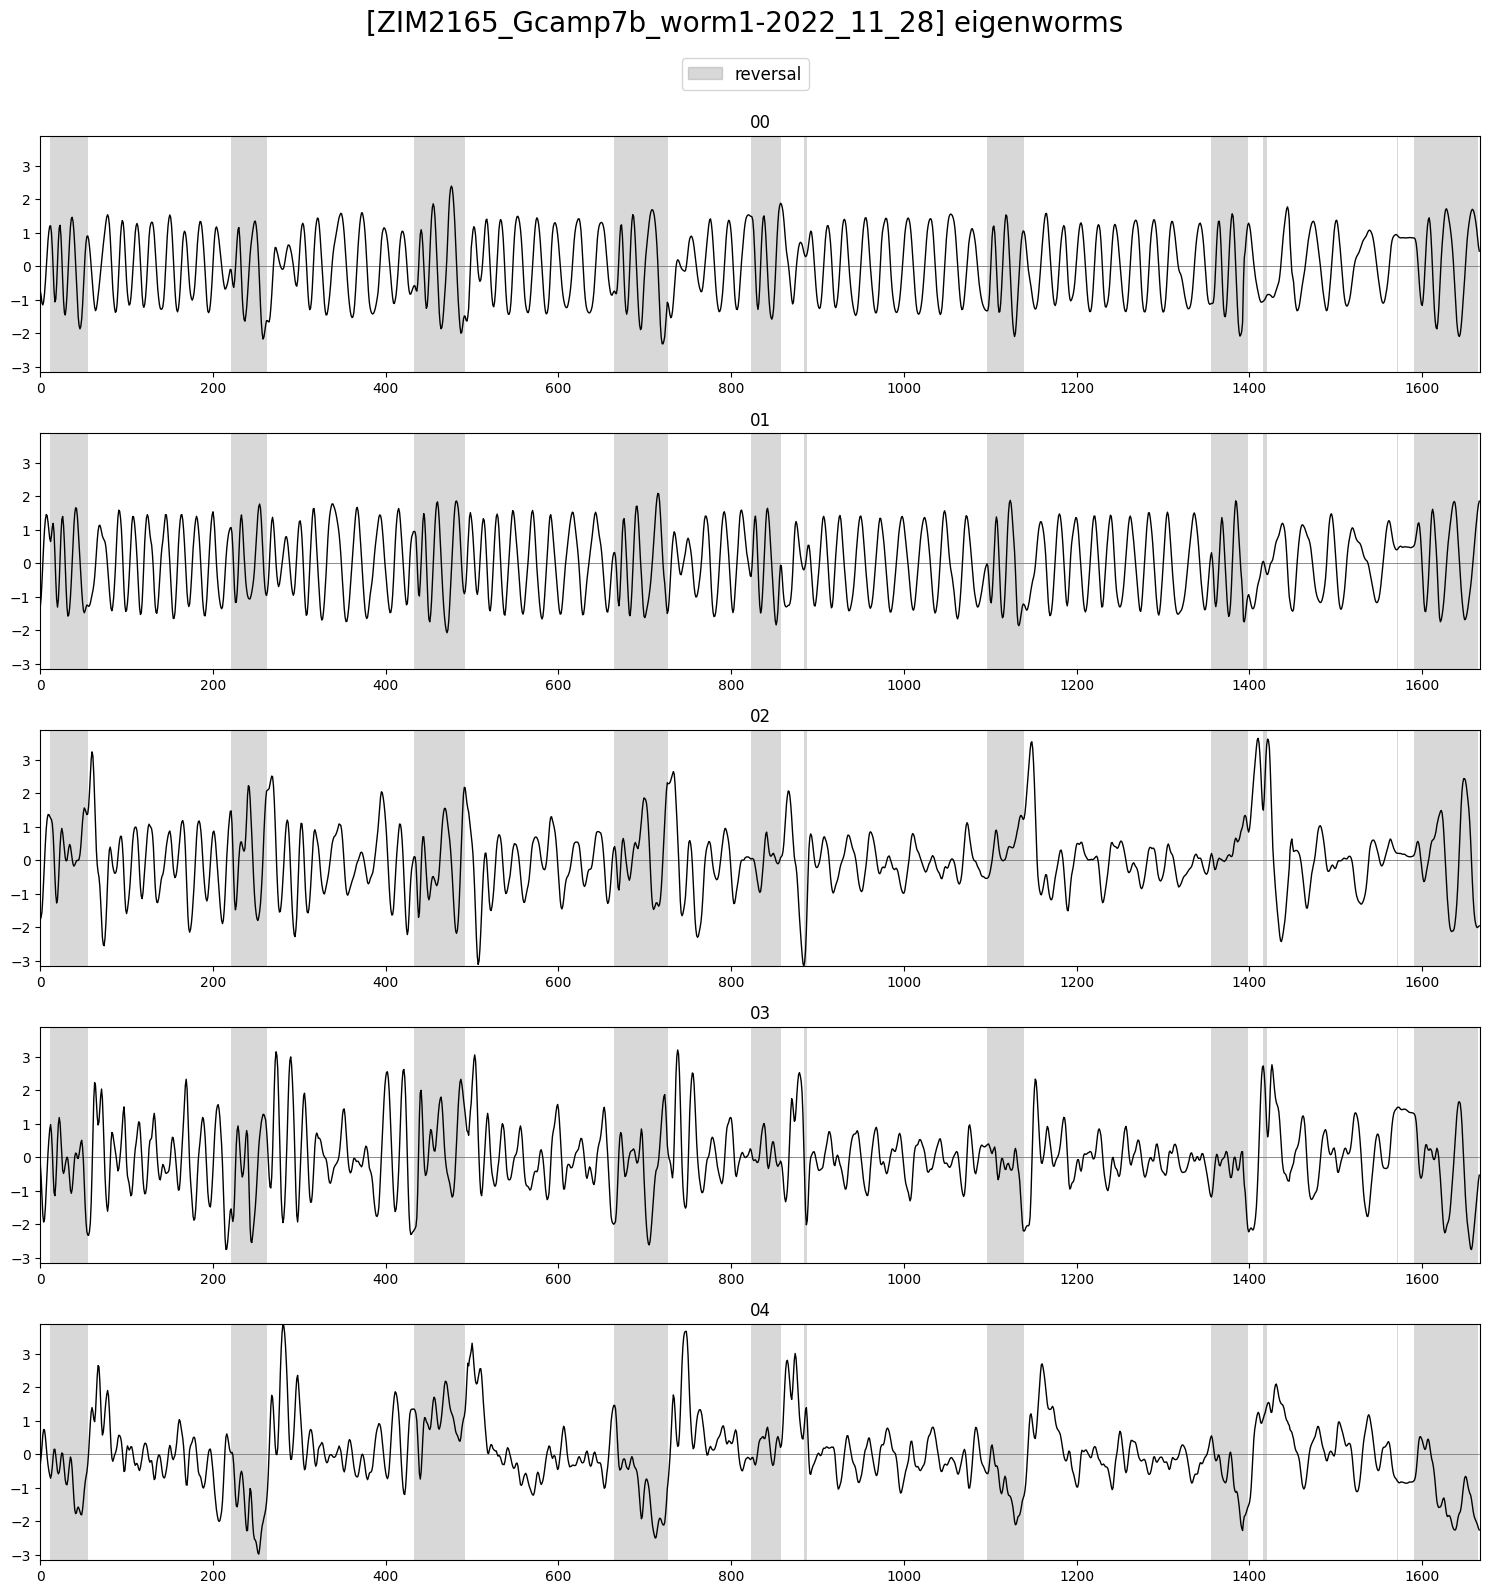

In [27]:
plot_utils.plot_traces(eigenworms,
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] eigenworms', ylimits=None, plots_per_row=1)

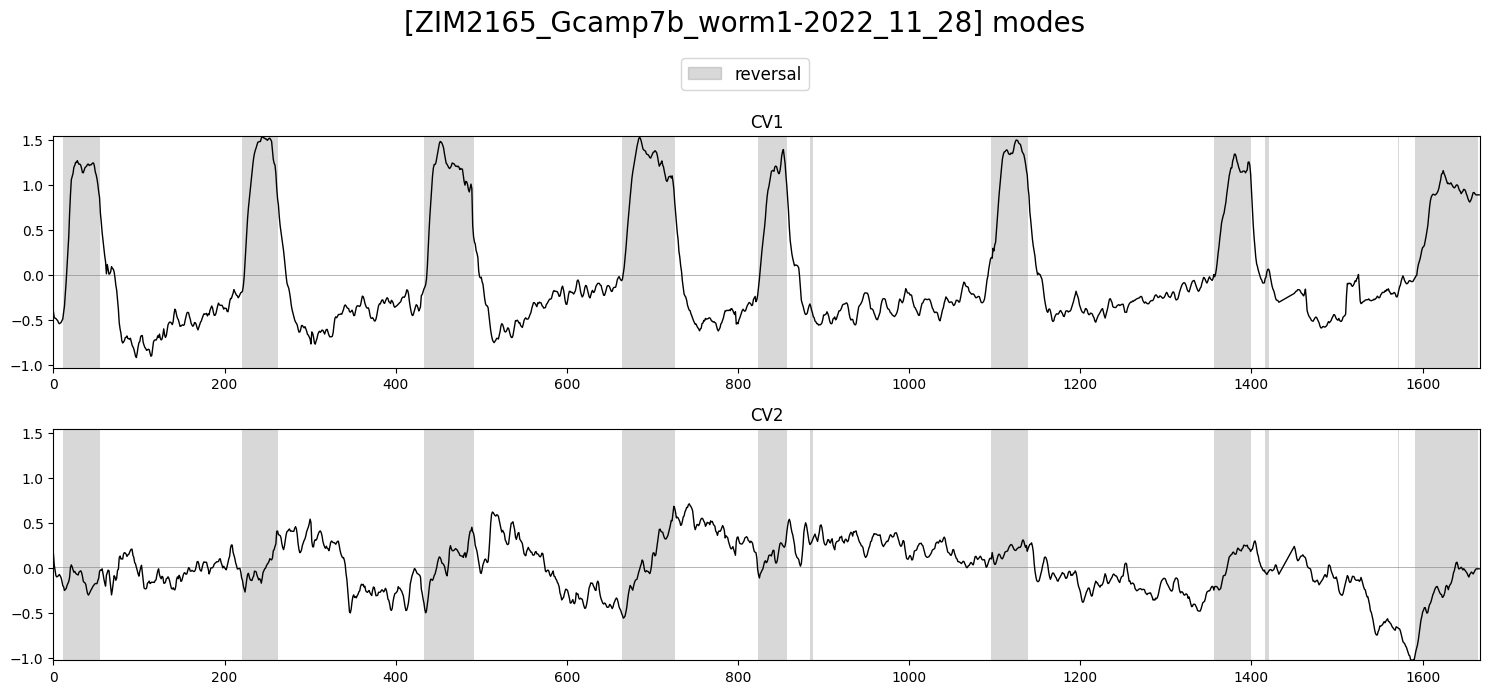

In [32]:
plot_utils.plot_traces(modes,
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] modes', ylimits=None, plots_per_row=1)

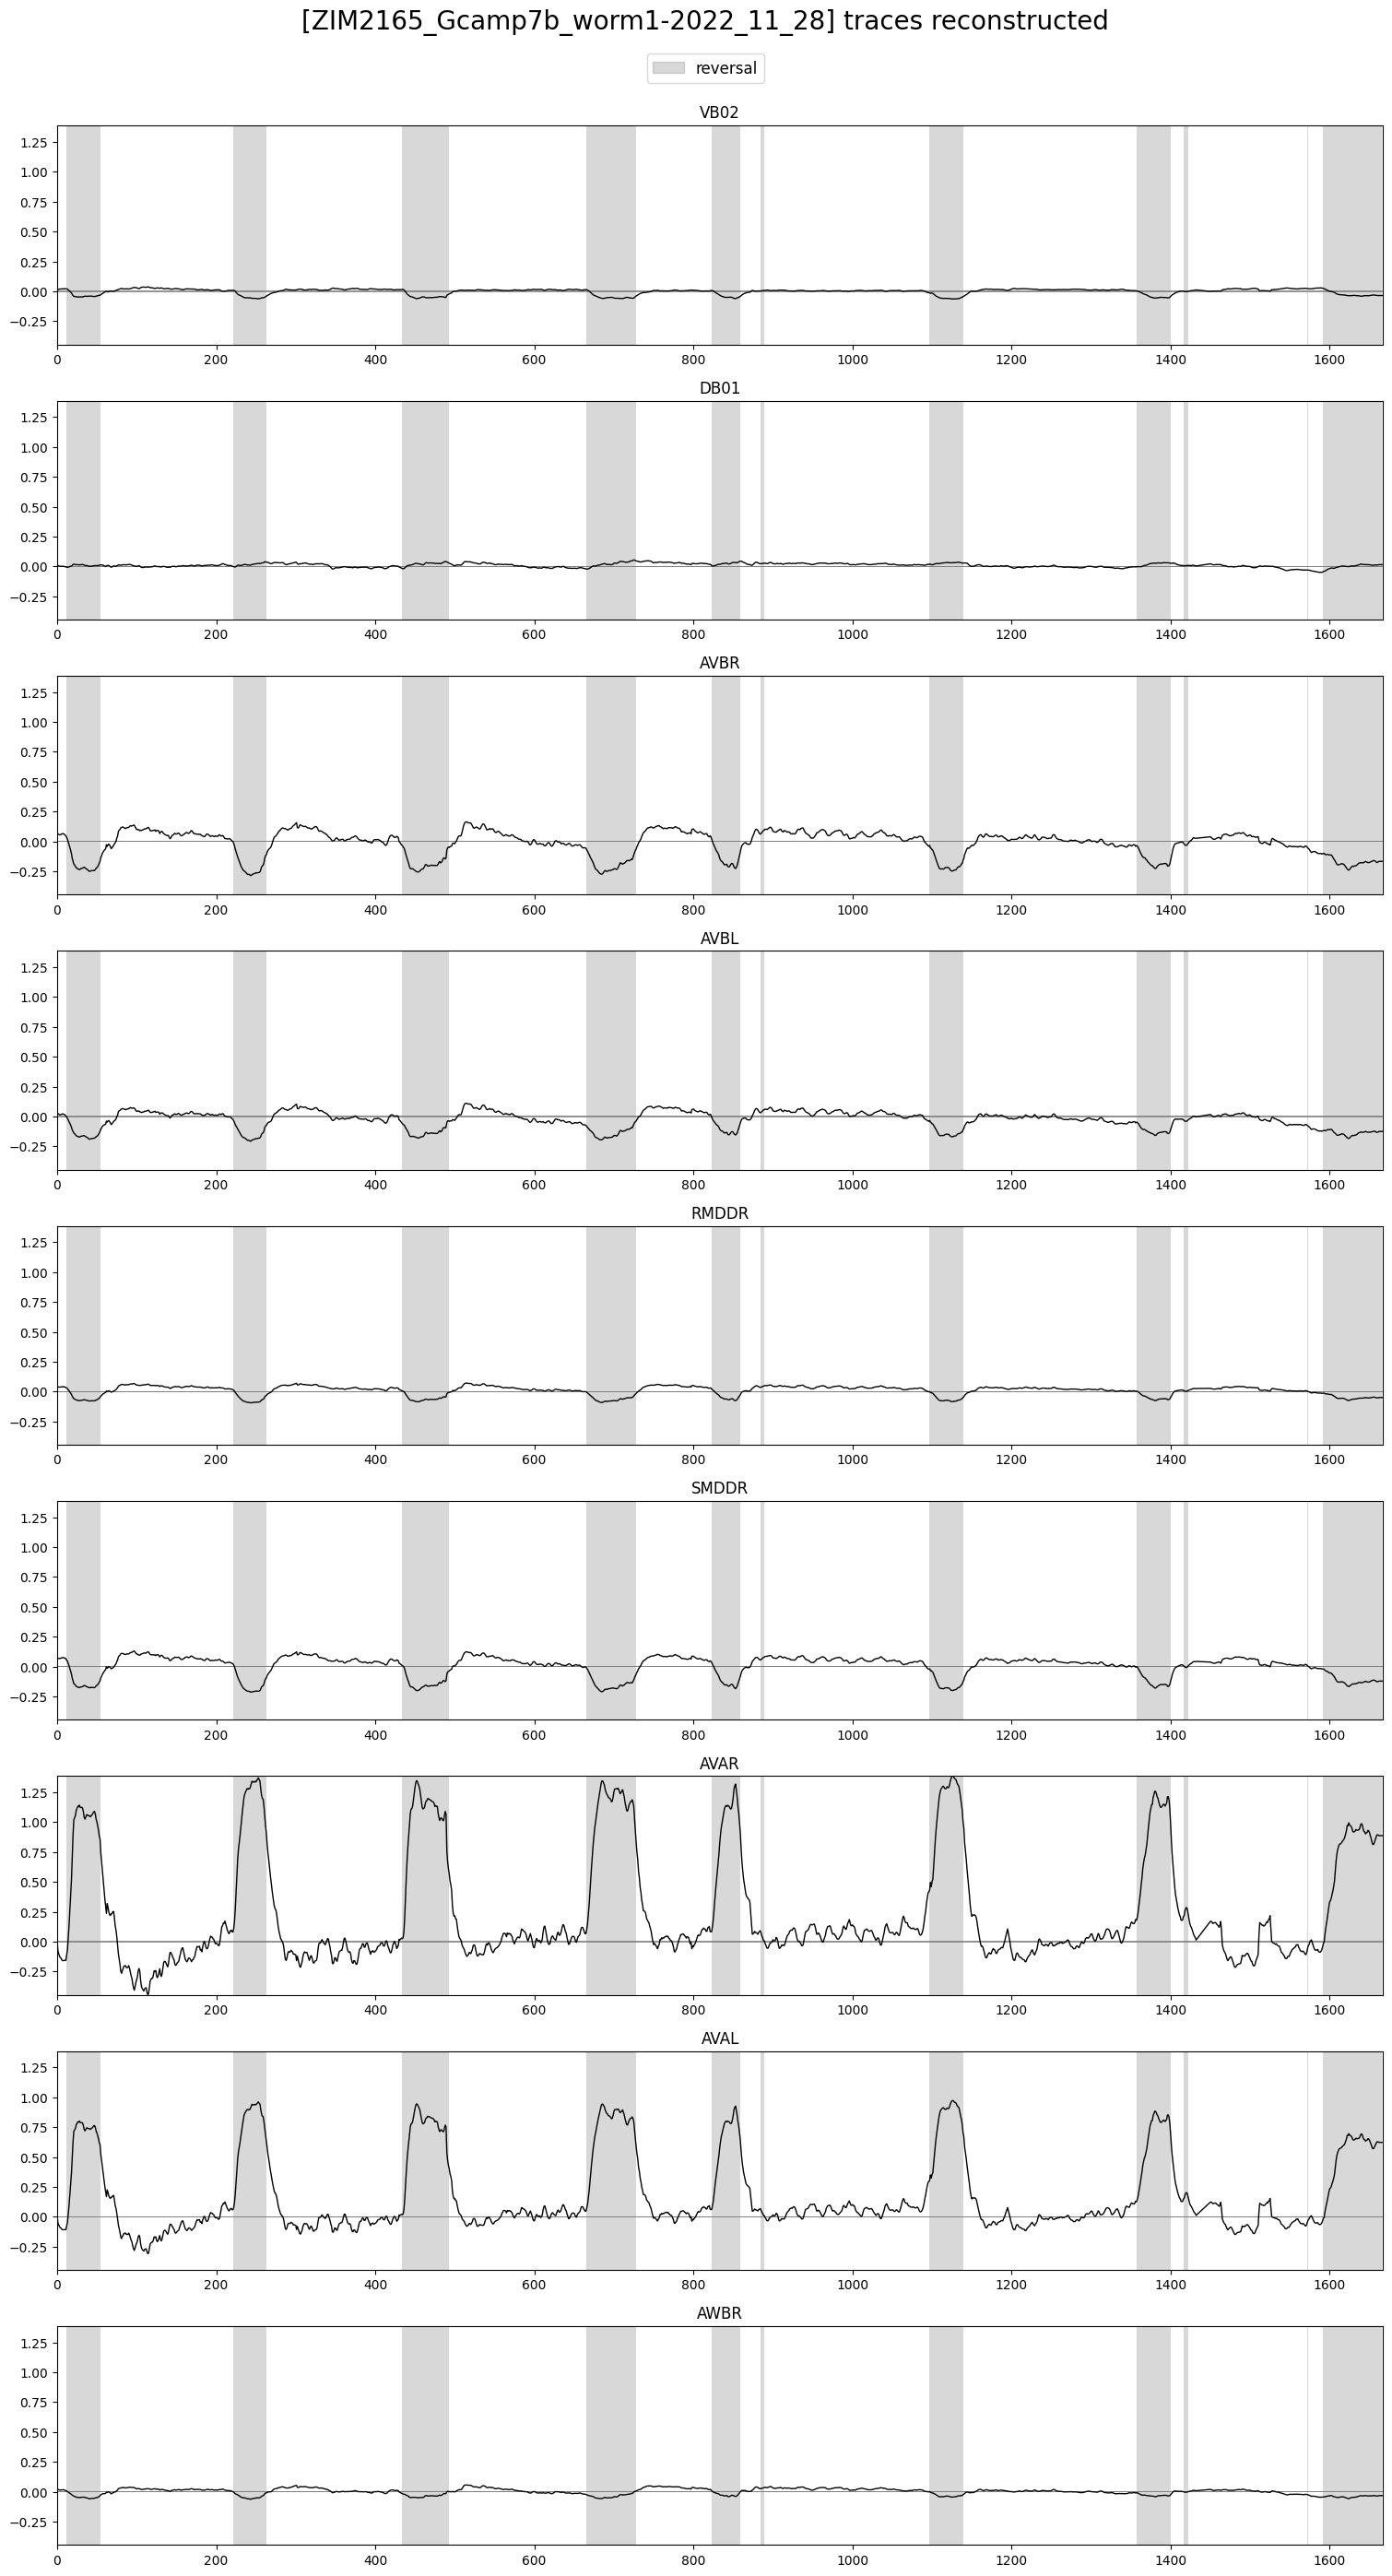

In [29]:
plot_utils.plot_traces(traces_reconstructed[selection_n],
					   discrete_states[['REV']],
					   ylimits=None, label='reversal',
					   title=f'[{filename}] traces reconstructed',
					   plots_per_row=1)

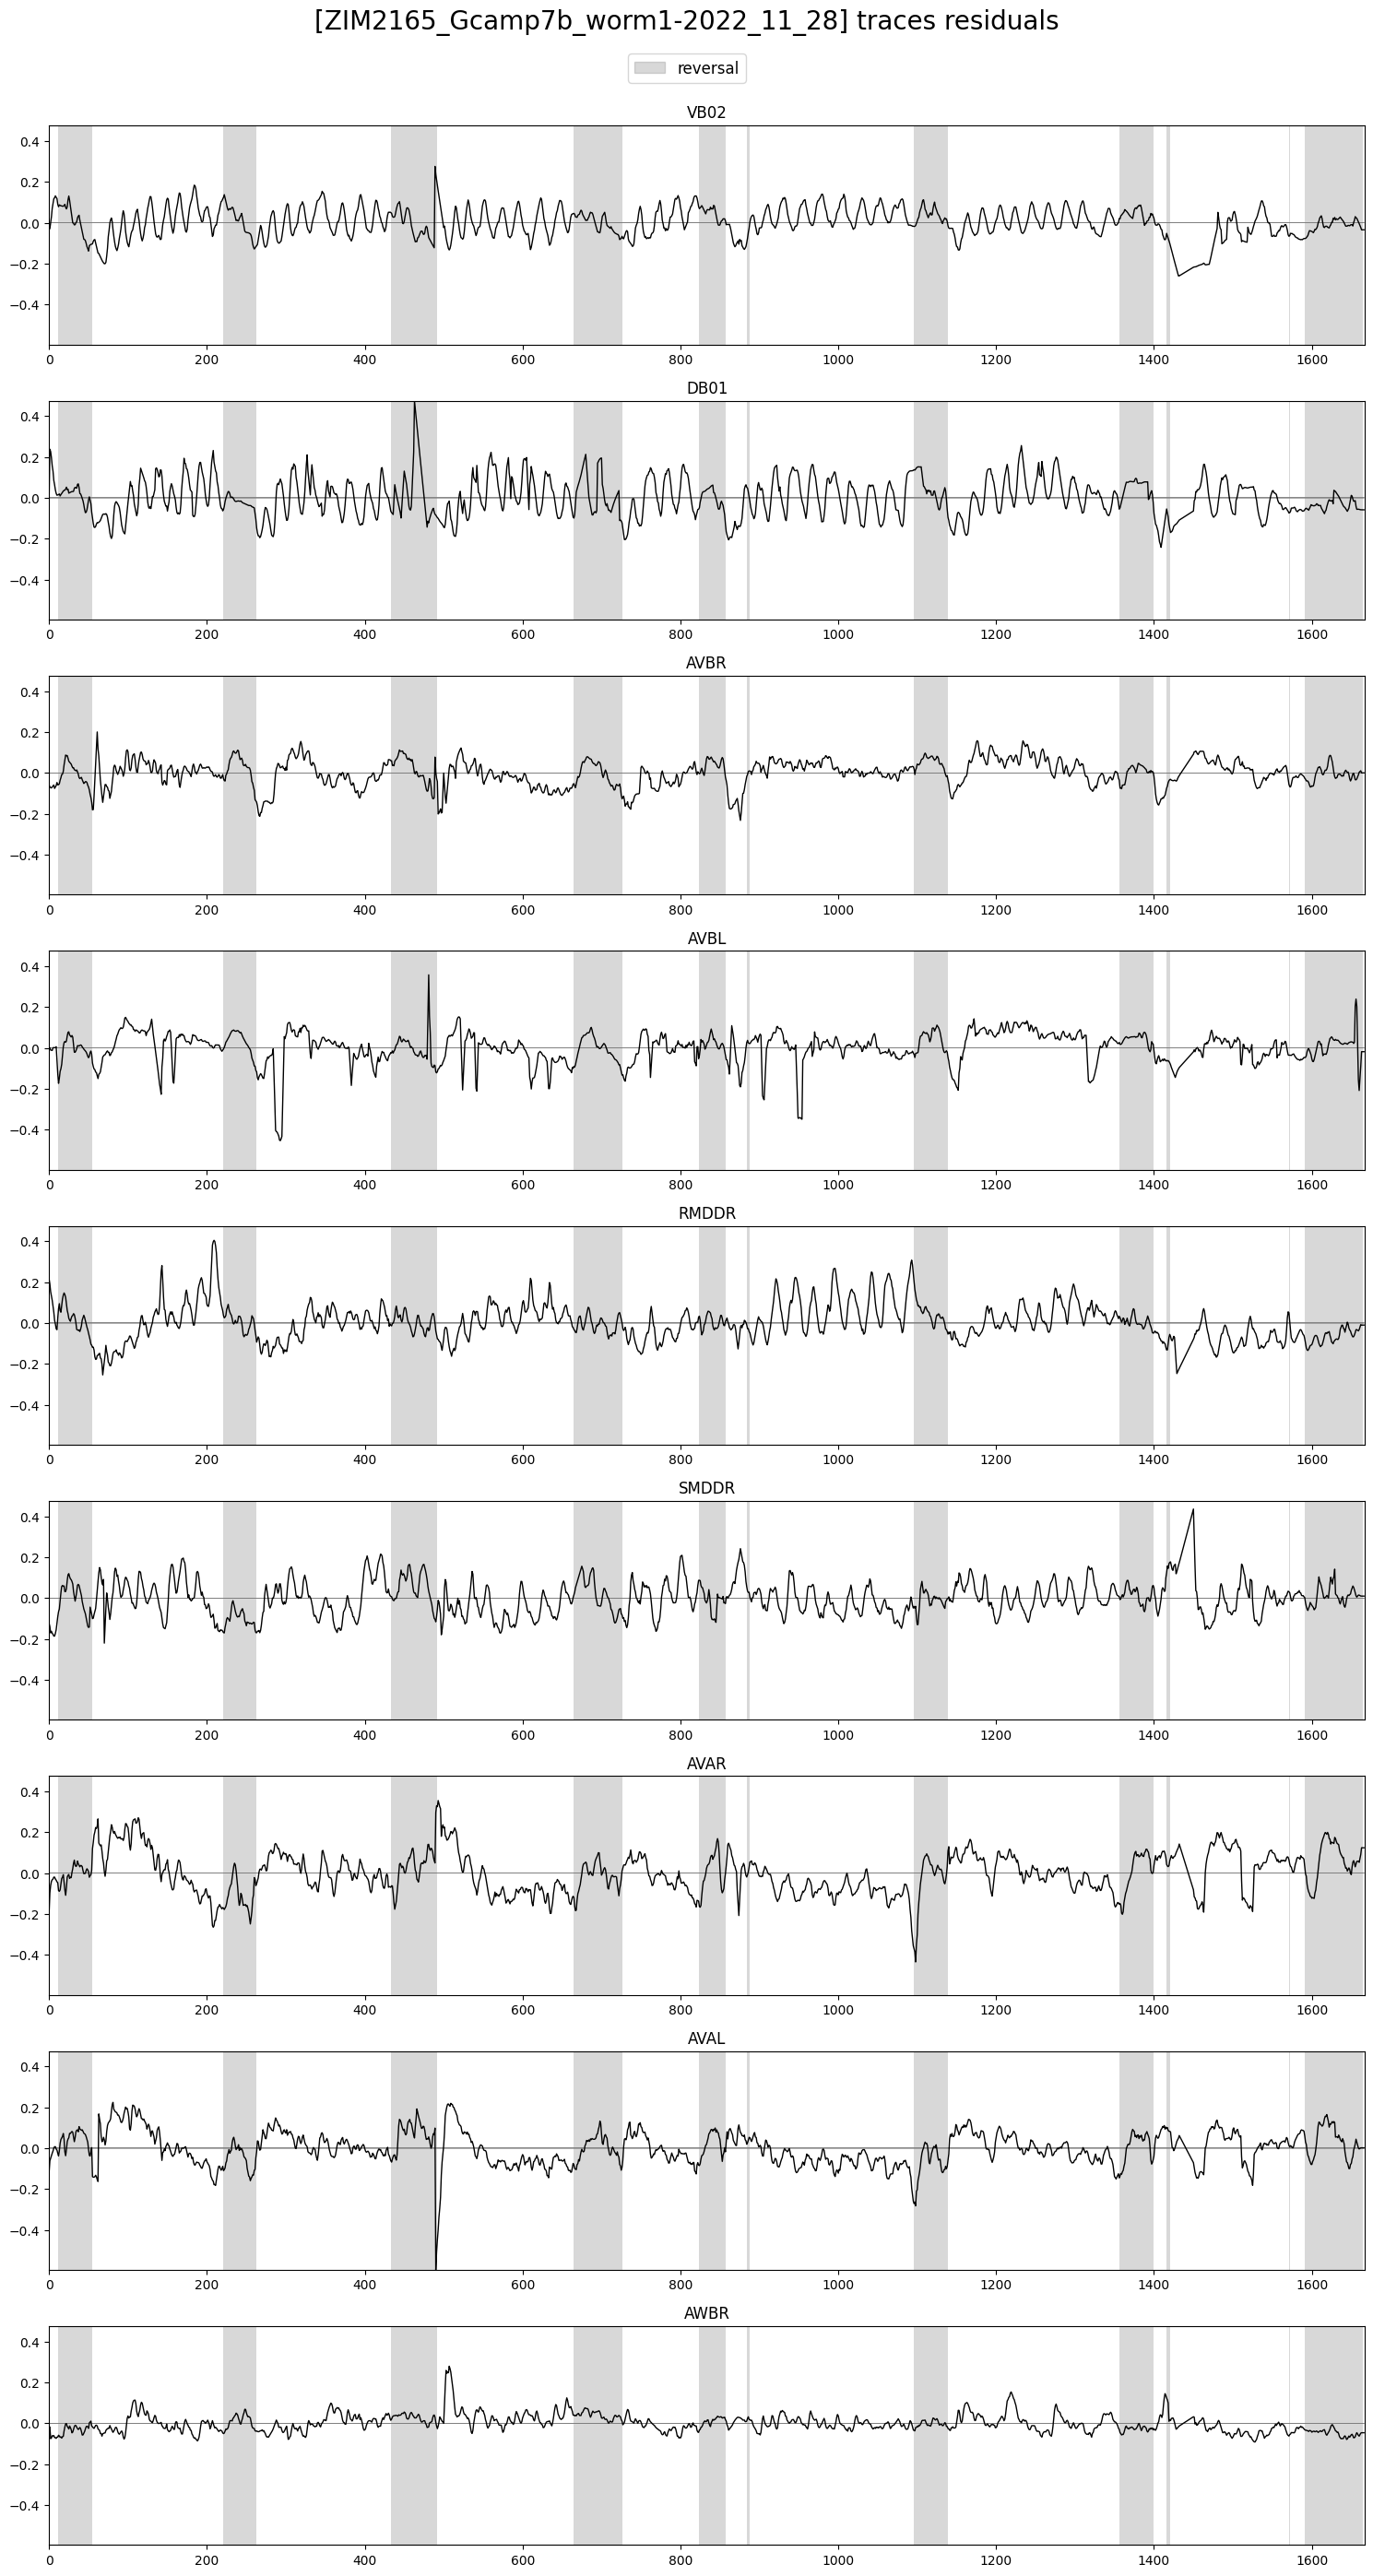

In [30]:
plot_utils.plot_traces(traces_residual[selection_n],
					   discrete_states[['REV']],
					   ylimits=None, label='reversal',
					   title=f'[{filename}] traces residuals',
					   plots_per_row=1)

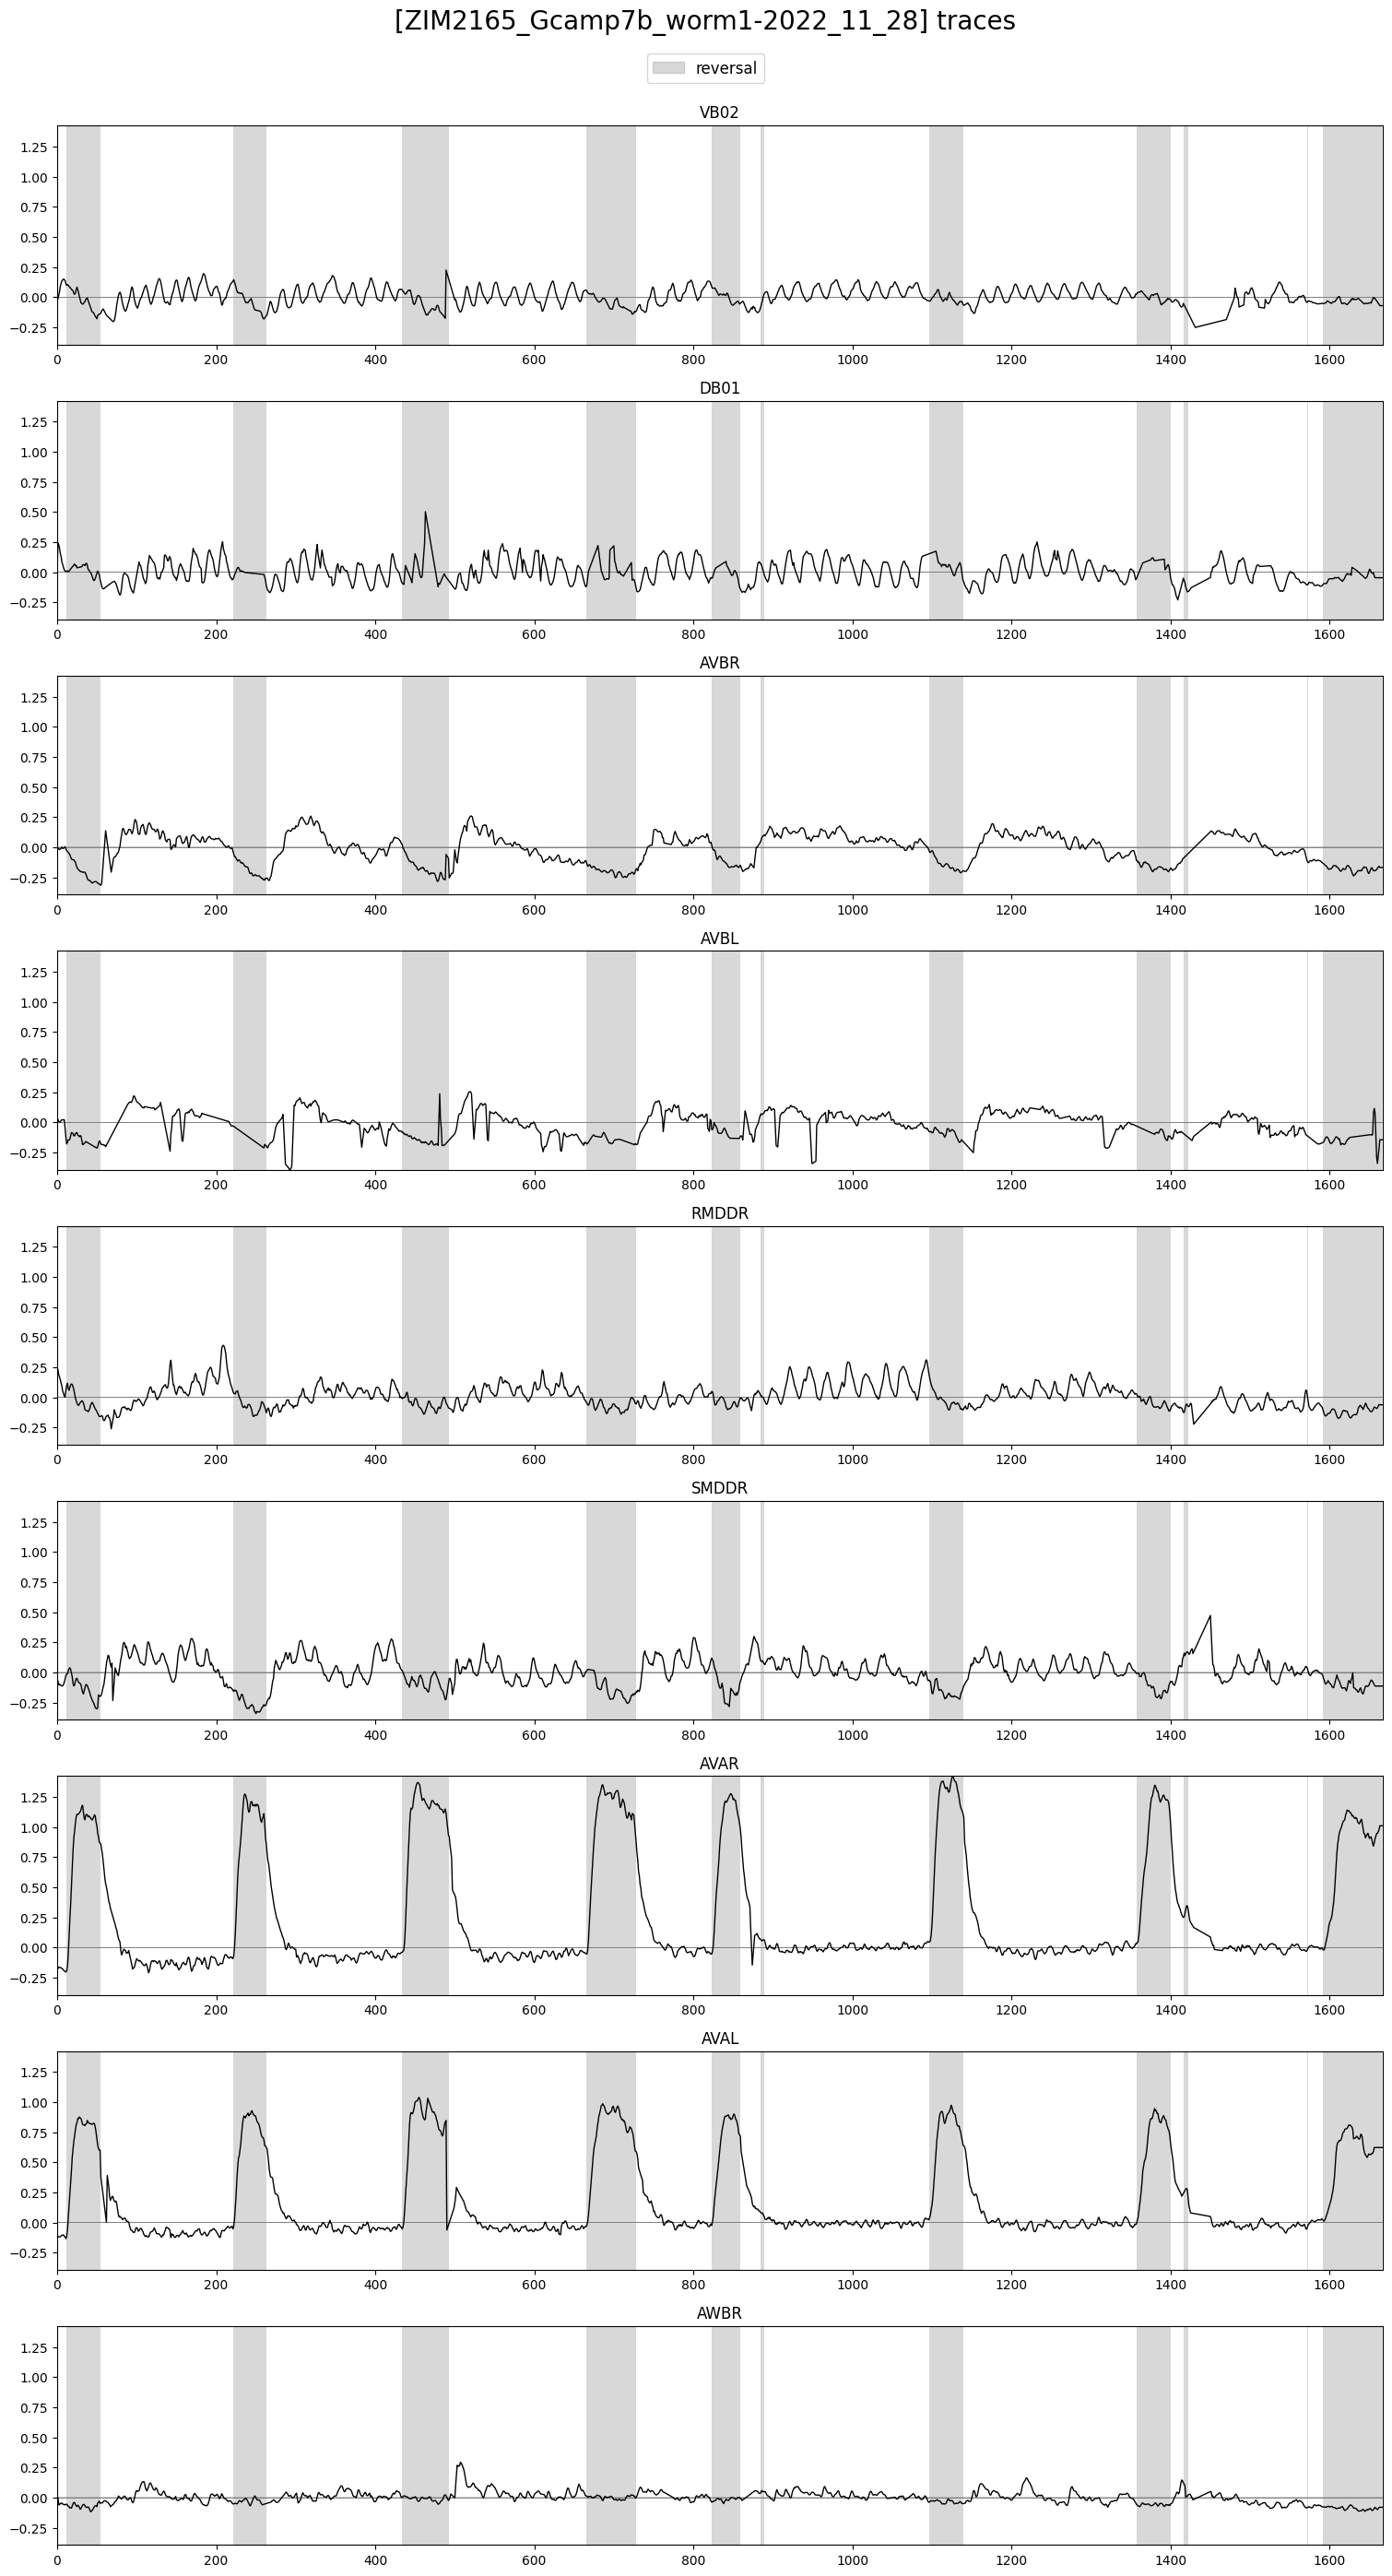

In [31]:
plot_utils.plot_traces(traces[selection_n],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] traces', ylimits=None, plots_per_row=1)